# ASVspoof 2019 LA — Spoof Detection
**Audio Transformer (coded here with `torch.nn.TransformerEncoder`) + pretrained AASIST (official ready-made model)**, fused into one classifier.

- **Branch A — AudioTransformer (built in this notebook):** log-mel spectrogram → patch embedding → `[CLS]` token + positional embedding → `nn.TransformerEncoder` → pooled embedding. Assembled layer by layer the same way the old `ASVSpoofCNN` was, but using PyTorch's own `TransformerEncoder` stack instead of hand-writing attention.
- **Branch B — AASIST (not built here):** the official `clovaai/aasist` model + its released pretrained weights, run on the raw waveform. It is downloaded and imported, not re-implemented.
- **Fusion head:** concatenates the two embeddings → MLP → bonafide / spoof. Each branch also has an auxiliary head so neither branch can be ignored during training (deep supervision).
- **Training:** Stage 1 trains the transformer + fusion head with AASIST frozen. Stage 2 ("fine-tune") unfreezes everything at a much smaller learning rate. Early stopping, L1/L2/dropout, SpecAugment, k-fold CV and full evaluation are kept.

In [2]:
import io
import sys
import math
import time
import urllib.request
import importlib.util
import os
import copy
import json
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from tqdm.auto import tqdm
from sklearn.model_selection import KFold
from sklearn.metrics import (
    roc_curve, auc, precision_recall_curve, precision_recall_fscore_support,
    confusion_matrix, classification_report,
)

## Config

In [3]:
DATA_DIR = r"C:\Users\navya\Downloads"
TRAIN_PATH = DATA_DIR + r"\train-00000-of-00001.parquet"
VAL_PATH   = DATA_DIR + r"\validation-00000-of-00001.parquet"
TEST_PATH  = DATA_DIR + r"\test-00000-of-00001.parquet"

SR = 16000
DURATION = 4
N_MELS = 128
WAVE_LEN = 64600          # AASIST's native input length (~4.04 s @ 16 kHz)
BATCH_SIZE = 24           # AASIST's official batch size; lower to 16 if you hit GPU OOM

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---- AudioTransformer
D_MODEL = 128
N_HEADS = 4
N_LAYERS = 4
FF_DIM = 256
PATCH = (16, 8)           # (mel bins, frames) per patch -> 8 x 15 = 120 tokens
SPEC_FREQ_MASK = 16       # SpecAugment (train only)
SPEC_TIME_MASK = 16

# ---- regularisation
DROPOUT_P = 0.3
L1_LAMBDA = 1e-5          # applied to the transformer branch only (see l1_penalty)
WEIGHT_DECAY = 1e-4
GRAD_CLIP = 5.0
AUX_WEIGHT = 0.3          # weight of the per-branch auxiliary losses
CLASS_WEIGHTS = None      # unweighted baseline (as in the previous experiment); e.g. [1.0, 0.25] to try weighting

# ---- optimisation: two-stage schedule
LR = 3e-4                 # stage 1: transformer + fusion head (AASIST frozen)
MAX_EPOCHS = 30
PATIENCE = 5
LR_FT = 3e-5              # stage 2: transformer + fusion head
LR_AASIST_FT = 1e-5       # stage 2: pretrained AASIST (kept small to preserve its weights)
FT_EPOCHS = 15
WARMUP_EPOCHS = 1         # linear warm-up, then cosine decay

N_FOLDS = 5
CV_EPOCHS = 10
CV_PATIENCE = 3

VERBOSE = True

# ---- AASIST (ready-made model, downloaded from the official repo)
AASIST_DIR = os.path.join(DATA_DIR, "aasist_repo")
AASIST_RAW = "https://raw.githubusercontent.com/clovaai/aasist/main/"
AASIST_CFG = {   # copied from the official config/AASIST.conf -> "model_config"
    "architecture": "AASIST", "nb_samp": 64600, "first_conv": 128,
    "filts": [70, [1, 32], [32, 32], [32, 64], [64, 64]],
    "gat_dims": [64, 32], "pool_ratios": [0.5, 0.7, 0.5, 0.5],
    "temperatures": [2.0, 2.0, 100.0, 100.0],
}

## Hyperparameter selection log
Initial values for the Transformer + AASIST system and where each one comes from. **These have not been tuned yet** — the "values_tried" column says so explicitly, so the table never claims experiments that were not run. Update it as you tune.

In [4]:
hyperparameter_table = pd.DataFrame([
    {"hyperparameter": "LR stage 1 (transformer + fusion)", "final_value": LR, "values_tried": "initial setting (not tuned)",
     "reason_for_choice": "Pre-norm transformers train stably at ~3e-4 with AdamW + warm-up; 1e-3 (used for the CNN) is usually too high for attention layers."},
    {"hyperparameter": "LR stage 2 (transformer + fusion)", "final_value": LR_FT, "values_tried": "initial setting (not tuned)",
     "reason_for_choice": "LR*0.1, same fine-tune ratio as the CNN notebook."},
    {"hyperparameter": "LR stage 2 (AASIST)", "final_value": LR_AASIST_FT, "values_tried": "initial setting (not tuned)",
     "reason_for_choice": "Official AASIST trains at 1e-4 -> 5e-6 (cosine); a smaller LR preserves the pretrained weights while adapting them to the fused objective."},
    {"hyperparameter": "Batch size", "final_value": BATCH_SIZE, "values_tried": "initial setting (not tuned)",
     "reason_for_choice": "24 is AASIST's official batch size; raw-waveform branch dominates GPU memory."},
    {"hyperparameter": "N_MELS", "final_value": N_MELS, "values_tried": "64, 128 (CNN experiments)",
     "reason_for_choice": "128 bands gave better val accuracy than 64 for the CNN; reused here."},
    {"hyperparameter": "d_model / heads / layers / FF", "final_value": f"{D_MODEL}/{N_HEADS}/{N_LAYERS}/{FF_DIM}", "values_tried": "initial setting (not tuned)",
     "reason_for_choice": "Small encoder (~0.56M params) comparable in size to AASIST (~0.30M) so neither branch swamps the other."},
    {"hyperparameter": "Patch size (mel, frames)", "final_value": str(PATCH), "values_tried": "initial setting (not tuned)",
     "reason_for_choice": "AST-style patches; gives 120 tokens for a 128x126 spectrogram, cheap for self-attention."},
    {"hyperparameter": "Dropout probability", "final_value": DROPOUT_P, "values_tried": "0.2, 0.3, 0.5 (CNN experiments)",
     "reason_for_choice": "0.3 gave the best train/val trade-off for the CNN; reused for the transformer and fusion head."},
    {"hyperparameter": "Weight decay (AdamW)", "final_value": WEIGHT_DECAY, "values_tried": "1e-3, 1e-4, 1e-5 (CNN experiments)",
     "reason_for_choice": "1e-4 (also AASIST's official value). Not applied to biases / norms / pos-embed / CLS."},
    {"hyperparameter": "L1 lambda (transformer branch)", "final_value": L1_LAMBDA, "values_tried": "1e-4, 1e-5, 0 (CNN experiments)",
     "reason_for_choice": "Mild sparsity pressure; restricted to the new transformer so pretrained AASIST weights are not pulled toward zero."},
    {"hyperparameter": "Auxiliary loss weight", "final_value": AUX_WEIGHT, "values_tried": "initial setting (not tuned)",
     "reason_for_choice": "Keeps each branch individually discriminative so the fusion head cannot rely on just one."},
    {"hyperparameter": "SpecAugment masks (freq/time)", "final_value": f"{SPEC_FREQ_MASK}/{SPEC_TIME_MASK}", "values_tried": "initial setting (not tuned)",
     "reason_for_choice": "Regularises the transformer branch against the train->eval attack mismatch in ASVspoof2019 LA."},
    {"hyperparameter": "Early stopping patience", "final_value": PATIENCE, "values_tried": "3, 5, 8 (CNN experiments)",
     "reason_for_choice": "5 epochs avoided stopping on val_loss noise."},
    {"hyperparameter": "K-fold CV folds", "final_value": N_FOLDS, "values_tried": "3, 5 (CNN experiments)",
     "reason_for_choice": "5-fold gave a stable estimate."},
])
print(hyperparameter_table.to_string(index=False))
hyperparameter_table.to_csv(os.path.join(DATA_DIR, "hyperparameter_tuning_log.csv"), index=False)

                   hyperparameter final_value                       values_tried                                                                                                                          reason_for_choice
LR stage 1 (transformer + fusion)      0.0003        initial setting (not tuned)        Pre-norm transformers train stably at ~3e-4 with AdamW + warm-up; 1e-3 (used for the CNN) is usually too high for attention layers.
LR stage 2 (transformer + fusion)     0.00003        initial setting (not tuned)                                                                                          LR*0.1, same fine-tune ratio as the CNN notebook.
              LR stage 2 (AASIST)     0.00001        initial setting (not tuned) Official AASIST trains at 1e-4 -> 5e-6 (cosine); a smaller LR preserves the pretrained weights while adapting them to the fused objective.
                       Batch size          24        initial setting (not tuned)                                        

In [5]:
def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

## Load data
Dataset is already split into train / validation / test parquet files.

In [6]:
train_df = pd.read_parquet(TRAIN_PATH)
val_df = pd.read_parquet(VAL_PATH)
test_df = pd.read_parquet(TEST_PATH)

print(train_df.shape, val_df.shape, test_df.shape)
print(train_df.columns.tolist())
train_df.head()

(25380, 5) (24844, 5) (71237, 5)
['speaker_id', 'audio_file_name', 'audio', 'system_id', 'key']


,speaker_id,audio_file_name,audio,system_id,key
0,LA_0079,LA_T_1138215,"{'bytes': b'fLaC\x00\x00\x00""\x04\x80\x04\x80\...",-,0
1,LA_0079,LA_T_1271820,"{'bytes': b'fLaC\x00\x00\x00""\x04\x80\x04\x80\...",-,0
2,LA_0079,LA_T_1272637,"{'bytes': b'fLaC\x00\x00\x00""\x04\x80\x04\x80\...",-,0
3,LA_0079,LA_T_1276960,"{'bytes': b'fLaC\x00\x00\x00""\x04\x80\x04\x80\...",-,0
4,LA_0079,LA_T_1341447,"{'bytes': b'fLaC\x00\x00\x00""\x04\x80\x04\x80\...",-,0


## Label mapping

In [7]:
LABEL_COL = next(c for c in ["label", "key", "target"] if c in train_df.columns)

def to_binary(v):
    if isinstance(v, str):
        return 0 if v.lower() == "bonafide" else 1
    return int(v)

for df in (train_df, val_df, test_df):
    df["y"] = df[LABEL_COL].apply(to_binary)

print(train_df["y"].value_counts(normalize=True))

y
1    0.898345
0    0.101655
Name: proportion, dtype: float64


## Dataset distribution & class imbalance analysis
Counts and percentages of `bonafide` vs `spoof` in each split, plus an explicit imbalance-ratio check (ASVspoof2019 LA is known to be spoof-heavy).

In [8]:
dist_rows = []
for split_name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    counts = df["y"].value_counts().sort_index()
    n_bonafide = int(counts.get(0, 0))
    n_spoof = int(counts.get(1, 0))
    total = n_bonafide + n_spoof
    dist_rows.append({
        "split": split_name,
        "n_bonafide": n_bonafide,
        "n_spoof": n_spoof,
        "total": total,
        "pct_bonafide": round(100 * n_bonafide / total, 2),
        "pct_spoof": round(100 * n_spoof / total, 2),
        "imbalance_ratio_spoof_to_bonafide": round(n_spoof / max(n_bonafide, 1), 2),
    })

dataset_distribution = pd.DataFrame(dist_rows)
print(dataset_distribution.to_string(index=False))

total_all = dataset_distribution["total"].sum()
for _, r in dataset_distribution.iterrows():
    print(f"{r['split']}: {r['total']} samples ({100*r['total']/total_all:.2f}% of all data)")

dataset_distribution.to_csv(os.path.join(DATA_DIR, "dataset_distribution.csv"), index=False)

     split  n_bonafide  n_spoof  total  pct_bonafide  pct_spoof  imbalance_ratio_spoof_to_bonafide
     train        2580    22800  25380         10.17      89.83                               8.84
validation        2548    22296  24844         10.26      89.74                               8.75
      test        7355    63882  71237         10.32      89.68                               8.69
train: 25380 samples (20.90% of all data)
validation: 24844 samples (20.45% of all data)
test: 71237 samples (58.65% of all data)


**Class imbalance note:** the `imbalance_ratio_spoof_to_bonafide` column shows how many spoof samples exist per bonafide sample in each split. ASVspoof2019 LA is spoof-heavy by construction (many more synthetic/converted attack utterances than genuine ones), which is why spoof-class recall/precision are reported separately in the results section rather than relying on plain accuracy alone.

## Audio decoding + feature extraction

In [9]:
AUDIO_COL = "audio" if "audio" in train_df.columns else next(
    c for c in train_df.columns if "audio" in c.lower() or "path" in c.lower()
)

def decode_audio(entry):
    if isinstance(entry, dict) and "bytes" in entry and entry["bytes"] is not None:
        wav, sr = sf.read(io.BytesIO(entry["bytes"]))
    elif isinstance(entry, dict) and "path" in entry:
        wav, sr = sf.read(entry["path"])
    elif isinstance(entry, (bytes, bytearray)):
        wav, sr = sf.read(io.BytesIO(entry))
    else:
        wav, sr = sf.read(entry)
    if wav.ndim > 1:
        wav = wav.mean(axis=1)
    if sr != SR:
        wav = librosa.resample(wav.astype(np.float32), orig_sr=sr, target_sr=SR)
    return wav.astype(np.float32)

def fix_length(wav, length=SR * DURATION):
    if len(wav) >= length:
        return wav[:length]
    return np.pad(wav, (0, length - len(wav)))

def to_melspec(wav):
    wav = fix_length(wav)
    mel = librosa.feature.melspectrogram(y=wav, sr=SR, n_mels=N_MELS)
    mel = librosa.power_to_db(mel, ref=np.max)
    mel = (mel - mel.mean()) / (mel.std() + 1e-6)
    return mel.astype(np.float32)

## Preprocessing parameter summary
Explicit table of every preprocessing parameter used, for the README / report.

In [10]:
preprocessing_params = pd.DataFrame([
    {"parameter": "Sample rate (SR)", "value": SR, "unit": "Hz"},
    {"parameter": "Clip duration", "value": DURATION, "unit": "seconds"},
    {"parameter": "Fixed waveform length", "value": SR * DURATION, "unit": "samples"},
    {"parameter": "Number of mel bands (N_MELS)", "value": N_MELS, "unit": "bands"},
    {"parameter": "Feature type", "value": "Log-mel spectrogram", "unit": "-"},
    {"parameter": "Mono conversion", "value": "channel-averaged if multi-channel", "unit": "-"},
    {"parameter": "AASIST raw-waveform length", "value": WAVE_LEN, "unit": "samples (first 64600, repeat-padded if shorter, as in official AASIST)"},
    {"parameter": "Waveform cache dtype", "value": "int16 (memory-mapped)", "unit": "-"},
    {"parameter": "Resampling", "value": "librosa.resample to SR if source sr differs", "unit": "-"},
])
print(preprocessing_params.to_string(index=False))
preprocessing_params.to_csv(os.path.join(DATA_DIR, "preprocessing_params.csv"), index=False)

                   parameter                                       value                                                                   unit
            Sample rate (SR)                                       16000                                                                     Hz
               Clip duration                                           4                                                                seconds
       Fixed waveform length                                       64000                                                                samples
Number of mel bands (N_MELS)                                         128                                                                  bands
                Feature type                         Log-mel spectrogram                                                                      -
             Mono conversion           channel-averaged if multi-channel                                                                

## Precompute & cache Mel spectrograms
Feature extraction is CPU-bound and was the actual training bottleneck (GPU sits idle waiting on `librosa` every batch). Compute each split's spectrograms once, cache to disk, and train on the cached arrays instead of recomputing every epoch.

In [11]:
CACHE_DIR = DATA_DIR

def precompute_features(df, split_name):
    x_path = os.path.join(CACHE_DIR, f"{split_name}_X_{N_MELS}mel.npy")
    y_path = os.path.join(CACHE_DIR, f"{split_name}_y_{N_MELS}mel.npy")
    if os.path.exists(x_path) and os.path.exists(y_path):
        X = np.load(x_path)
        y = np.load(y_path)
        print(f"{split_name}: loaded cached features {X.shape}")
        return X, y

    audio_col = df[AUDIO_COL].values
    labels = df["y"].values.astype(np.int64)
    first_mel = to_melspec(decode_audio(audio_col[0]))
    X = np.zeros((len(df), *first_mel.shape), dtype=np.float32)
    X[0] = first_mel
    for i in tqdm(range(1, len(df)), desc=f"precompute {split_name}"):
        X[i] = to_melspec(decode_audio(audio_col[i]))

    np.save(x_path, X)
    np.save(y_path, labels)
    print(f"{split_name}: cached features {X.shape} -> {x_path}")
    return X, labels

## Precompute & cache raw waveforms (for AASIST)
AASIST consumes the raw waveform, so each split's waveforms are decoded once and stored as a **memory-mapped int16 `.npy`** (exact for 16-bit audio, 2 bytes/sample, and not loaded into RAM). Roughly 2 bytes x 64,600 x N clips on disk (about 130 KB per clip).

In [12]:
def fix_wave(wav, length=WAVE_LEN):
    # identical to the official AASIST pad(): truncate, or tile if too short
    if len(wav) >= length:
        return wav[:length]
    reps = int(np.ceil(length / len(wav)))
    return np.tile(wav, reps)[:length]

def precompute_waveforms(df, split_name):
    path = os.path.join(CACHE_DIR, f"{split_name}_wave_{WAVE_LEN}_int16.npy")
    if os.path.exists(path):
        W = np.load(path, mmap_mode="r")
        print(f"{split_name}: loaded cached waveforms {W.shape}")
        return W
    tmp = path[:-4] + ".partial.npy"            # never leave a half-written file that looks like a cache
    audio_col = df[AUDIO_COL].values
    W = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.int16, shape=(len(df), WAVE_LEN))
    for i in tqdm(range(len(df)), desc=f"waveforms {split_name}"):
        wav = fix_wave(decode_audio(audio_col[i]))
        W[i] = np.clip(np.round(wav * 32768.0), -32768, 32767).astype(np.int16)
    W.flush()
    del W
    os.replace(tmp, path)
    W = np.load(path, mmap_mode="r")
    print(f"{split_name}: cached waveforms {W.shape} -> {path}")
    return W

## Cached Dataset
Returns `(log-mel, raw waveform, label)`. No CPU feature work happens in `__getitem__`.

In [13]:
class CachedMelWaveDataset(Dataset):
    def __init__(self, X, W, y):
        assert len(X) == len(W) == len(y)
        self.X, self.W, self.y = X, W, y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        mel = torch.from_numpy(self.X[idx]).unsqueeze(0)                         # (1, n_mels, frames)
        wave = torch.from_numpy(np.asarray(self.W[idx], dtype=np.float32) / 32768.0)  # (WAVE_LEN,) in [-1, 1)
        y = torch.tensor(self.y[idx], dtype=torch.long)
        return mel, wave, y

## Build cached datasets + DataLoaders

In [14]:
X_train, y_train = precompute_features(train_df, "train")
X_val, y_val = precompute_features(val_df, "validation")
X_test, y_test = precompute_features(test_df, "test")

W_train = precompute_waveforms(train_df, "train")
W_val = precompute_waveforms(val_df, "validation")
W_test = precompute_waveforms(test_df, "test")

N_FRAMES = X_train.shape[-1]
print("mel shape:", X_train.shape[1:], "| waveform length:", W_train.shape[1])

train_loader = DataLoader(CachedMelWaveDataset(X_train, W_train, y_train), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(CachedMelWaveDataset(X_val, W_val, y_val), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(CachedMelWaveDataset(X_test, W_test, y_test), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

train: loaded cached features (25380, 128, 126)
validation: loaded cached features (24844, 128, 126)
test: loaded cached features (71237, 128, 126)
train: loaded cached waveforms (25380, 64600)
validation: loaded cached waveforms (24844, 64600)
test: loaded cached waveforms (71237, 64600)
mel shape: (128, 126) | waveform length: 64600


## Model — AudioTransformer + AASIST (hybrid)

### Fetch the ready-made AASIST
`models/AASIST.py` and the released pretrained weights are downloaded from the official `clovaai/aasist` repository and imported as a module — nothing from AASIST is re-implemented here. (If the download is blocked, `git clone https://github.com/clovaai/aasist` and point `AASIST_DIR` at it; the notebook needs `AASIST_DIR/models/AASIST.py` and `AASIST_DIR/models/weights/AASIST.pth`.)

In [15]:
def fetch_aasist():
    os.makedirs(os.path.join(AASIST_DIR, "models", "weights"), exist_ok=True)
    for rel in ["models/AASIST.py", "models/weights/AASIST.pth"]:
        dst = os.path.join(AASIST_DIR, *rel.split("/"))
        if not os.path.exists(dst):
            print("downloading", rel)
            urllib.request.urlretrieve(AASIST_RAW + rel, dst)
    spec = importlib.util.spec_from_file_location("aasist_official", os.path.join(AASIST_DIR, "models", "AASIST.py"))
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod.Model, os.path.join(AASIST_DIR, "models", "weights", "AASIST.pth")

AASISTModel, AASIST_WEIGHTS = fetch_aasist()
print("AASIST ready:", AASIST_WEIGHTS)

AASIST ready: C:\Users\navya\Downloads\aasist_repo\models\weights\AASIST.pth


### AudioTransformer — built here, layer by layer (like the old CNN)

| Stage | Layers | Output |
|---|---|---|
| SpecAugment (train only) | 2 frequency masks + 2 time masks | (B, 1, 128, T) |
| Patch embedding | `Conv2d(1, d_model, kernel=PATCH, stride=PATCH)` → flatten | (B, 120, d_model) |
| Tokens | prepend learned `[CLS]`, add learned positional embedding, Dropout | (B, 121, d_model) |
| Encoder | `nn.TransformerEncoder` × `N_LAYERS` (pre-norm, GELU, multi-head self-attention) + final LayerNorm | (B, 121, d_model) |
| Pooling | concat(`[CLS]`, mean of patch tokens) | (B, 2·d_model) |

### Hybrid classifier
`[transformer embedding (256) ‖ AASIST embedding (160)]` → LayerNorm → Dropout → Linear(416→128) → GELU → Dropout → Linear(128→2).
Auxiliary heads: `Linear(256→2)` on the transformer embedding, and AASIST's own pretrained 2-way output (index-swapped, because AASIST uses *1 = bonafide* whereas this notebook uses *1 = spoof*).

In [16]:
class AudioTransformer(nn.Module):
    def __init__(self, n_mels=N_MELS, n_frames=N_FRAMES, d_model=D_MODEL, nhead=N_HEADS, num_layers=N_LAYERS,
                 dim_ff=FF_DIM, patch=PATCH, dropout_p=DROPOUT_P):
        super().__init__()
        self.freq_mask, self.time_mask = SPEC_FREQ_MASK, SPEC_TIME_MASK
        self.patch_embed = nn.Conv2d(1, d_model, kernel_size=patch, stride=patch)
        fh = (n_mels - patch[0]) // patch[0] + 1
        fw = (n_frames - patch[1]) // patch[1] + 1
        self.n_tokens = fh * fw
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.n_tokens + 1, d_model))
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        self.token_drop = nn.Dropout(dropout_p)
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, dim_feedforward=dim_ff, dropout=dropout_p,
                                           activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers, norm=nn.LayerNorm(d_model),
                                             enable_nested_tensor=False)
        self.embed_dim = 2 * d_model

    def spec_augment(self, x):
        B, _, Fq, T = x.shape
        fr = torch.arange(Fq, device=x.device).view(1, 1, Fq, 1)
        tr = torch.arange(T, device=x.device).view(1, 1, 1, T)
        for _ in range(2):
            w = torch.randint(0, self.freq_mask + 1, (B, 1, 1, 1), device=x.device)
            s = (torch.rand(B, 1, 1, 1, device=x.device) * (Fq - w)).long()
            x = x.masked_fill((fr >= s) & (fr < s + w), 0.0)       # inputs are zero-mean, so 0 = "mean" fill
            w = torch.randint(0, self.time_mask + 1, (B, 1, 1, 1), device=x.device)
            s = (torch.rand(B, 1, 1, 1, device=x.device) * (T - w)).long()
            x = x.masked_fill((tr >= s) & (tr < s + w), 0.0)
        return x

    def forward(self, mel):
        if self.training:
            mel = self.spec_augment(mel)
        x = self.patch_embed(mel).flatten(2).transpose(1, 2)               # (B, tokens, d_model)
        x = torch.cat([self.cls_token.expand(x.size(0), -1, -1), x], dim=1) + self.pos_embed
        x = self.encoder(self.token_drop(x))
        return torch.cat([x[:, 0], x[:, 1:].mean(dim=1)], dim=1)           # (B, 2*d_model)


class HybridTransformerAASIST(nn.Module):
    def __init__(self, dropout_p=DROPOUT_P, pretrained_aasist=True):
        super().__init__()
        self.transformer = AudioTransformer()
        self.aasist = AASISTModel(AASIST_CFG)
        if pretrained_aasist:
            self.aasist.load_state_dict(torch.load(AASIST_WEIGHTS, map_location="cpu"))
        a_dim = 5 * AASIST_CFG["gat_dims"][1]                              # 160
        t_dim = self.transformer.embed_dim
        self.trans_head = nn.Linear(t_dim, 2)                              # auxiliary head (transformer)
        self.fusion = nn.Sequential(
            nn.LayerNorm(t_dim + a_dim), nn.Dropout(dropout_p),
            nn.Linear(t_dim + a_dim, 128), nn.GELU(), nn.Dropout(dropout_p),
            nn.Linear(128, 2),
        )
        self.aasist_frozen = False
        self.use_cached_aasist = False                                     # CV speed-up: 2nd input = cached AASIST outputs
        self.a_dim = a_dim

    def set_aasist_trainable(self, trainable):
        self.aasist_frozen = not trainable
        for p in self.aasist.parameters():
            p.requires_grad = trainable

    def _run(self, mel, wave):
        t_emb = self.transformer(mel)
        if self.use_cached_aasist:
            a_emb, a_out = wave[:, :self.a_dim], wave[:, self.a_dim:]       # (B,160) embedding, (B,2) AASIST logits
        elif self.aasist_frozen:
            self.aasist.eval()                                             # keep BN/dropout fixed while frozen
            with torch.no_grad():
                a_emb, a_out = self.aasist(wave)
        else:
            a_emb, a_out = self.aasist(wave)
        a_logits = a_out[:, [1, 0]]                                        # AASIST: 1=bonafide -> here: 1=spoof
        fused = self.fusion(torch.cat([t_emb, a_emb], dim=1))
        return fused, self.trans_head(t_emb), a_logits

    def forward(self, mel, wave):
        fused, t_logits, a_logits = self._run(mel, wave)
        if self.training:
            return fused, t_logits, a_logits                               # main + auxiliary heads
        return fused


def build_hybrid():
    return HybridTransformerAASIST().to(DEVICE)

### Model size — parameter count

In [17]:
def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


_tmp_model = build_hybrid()
total_params, trainable_params = count_parameters(_tmp_model)
t_p = sum(p.numel() for p in _tmp_model.transformer.parameters())
a_p = sum(p.numel() for p in _tmp_model.aasist.parameters())
print(f"Hybrid — total params: {total_params:,} | transformer branch: {t_p:,} | AASIST branch: {a_p:,} | "
      f"fusion + aux heads: {total_params - t_p - a_p:,}")
del _tmp_model

Hybrid — total params: 915,150 | transformer branch: 562,304 | AASIST branch: 297,866 | fusion + aux heads: 54,980


## Early stopping

In [18]:
class EarlyStopping:
    def __init__(self, patience=PATIENCE, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.best_state = None
        self.best_epoch = -1
        self.counter = 0
        self.stop = False

    def step(self, val_loss, model, epoch):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.best_state = copy.deepcopy(model.state_dict())
            self.best_epoch = epoch
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True

## Training / evaluation utilities
- `MultiHeadCE`: cross-entropy on the fused head + `AUX_WEIGHT` × cross-entropy on each auxiliary head (training only). **Logged train/val loss is the fused-head CE**, so the two curves are comparable.
- AdamW with separate learning rates for the transformer/fusion group and the AASIST group; no weight decay on biases, norms, positional embedding or `[CLS]`.
- Linear warm-up + cosine decay (stepped per batch), gradient clipping.
- L1 (Lasso) penalty on the transformer branch only; L2 via AdamW `weight_decay`.

In [19]:
class MultiHeadCE(nn.Module):
    def __init__(self, aux_weight=AUX_WEIGHT, class_weights=CLASS_WEIGHTS):
        super().__init__()
        w = None if class_weights is None else torch.tensor(class_weights, dtype=torch.float32)
        self.register_buffer("w", w)
        self.aux_weight = aux_weight

    def main_ce(self, logits, y):
        return F.cross_entropy(logits, y, weight=None if self.w is None else self.w.to(logits.device))

    def forward(self, out, y):
        if isinstance(out, tuple):
            return self.main_ce(out[0], y) + self.aux_weight * sum(self.main_ce(o, y) for o in out[1:])
        return self.main_ce(out, y)


def l1_penalty(model):
    return sum(p.abs().sum() for name, p in model.transformer.named_parameters() if "weight" in name and p.dim() > 1)


def build_optimizer(model, lr, lr_aasist, weight_decay):
    groups = []
    for params_lr, is_aasist in [(lr, False), (lr_aasist, True)]:
        decay, no_decay = [], []
        for n, p in model.named_parameters():
            if not p.requires_grad or n.startswith("aasist.") != is_aasist:
                continue
            nodecay = p.ndim < 2 or "pos_embed" in n or "cls_token" in n
            (no_decay if nodecay else decay).append(p)
        if decay:
            groups.append({"params": decay, "lr": params_lr, "weight_decay": weight_decay})
        if no_decay:
            groups.append({"params": no_decay, "lr": params_lr, "weight_decay": 0.0})
    return torch.optim.AdamW(groups)


def build_scheduler(optimizer, total_steps, warmup_steps, min_ratio=0.01):
    def fn(step):
        if step < warmup_steps:
            return (step + 1) / max(warmup_steps, 1)
        prog = (step - warmup_steps) / max(total_steps - warmup_steps, 1)
        return min_ratio + (1 - min_ratio) * 0.5 * (1 + math.cos(math.pi * min(prog, 1.0)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, fn)


def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, l1_lambda=0.0, tag=""):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    total_loss, correct, n = 0.0, 0, 0
    iterator = tqdm(loader, desc=tag, leave=False) if VERBOSE else loader
    with torch.set_grad_enabled(is_train):
        for mel, wave, y in iterator:
            mel, wave, y = mel.to(DEVICE), wave.to(DEVICE), y.to(DEVICE)
            out = model(mel, wave)
            main = out[0] if isinstance(out, tuple) else out
            loss = criterion(out, y)
            if is_train and l1_lambda > 0:
                loss = loss + l1_lambda * l1_penalty(model)
            if is_train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                optimizer.step()
                if scheduler is not None:
                    scheduler.step()
            main_loss = criterion.main_ce(main, y).item()
            total_loss += main_loss * y.size(0)
            preds = main.argmax(1)
            correct += (preds == y).sum().item()
            n += y.size(0)
            if VERBOSE and hasattr(iterator, "set_postfix"):
                iterator.set_postfix(loss=f"{main_loss:.4f}", acc=f"{(preds == y).float().mean().item():.4f}")
    return total_loss / n, correct / n


def train_model(model, train_loader_, val_loader_, epochs, lr, lr_aasist=0.0, weight_decay=0.0, l1_lambda=0.0,
                patience=PATIENCE, tag="", warmup_epochs=WARMUP_EPOCHS):
    criterion = MultiHeadCE().to(DEVICE)
    optimizer = build_optimizer(model, lr, lr_aasist, weight_decay)
    total_steps = epochs * len(train_loader_)
    scheduler = build_scheduler(optimizer, total_steps, warmup_epochs * len(train_loader_))
    stopper = EarlyStopping(patience=patience)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(epochs):
        tr_loss, tr_acc = run_epoch(model, train_loader_, criterion, optimizer, scheduler, l1_lambda=l1_lambda, tag=f"{tag} train e{epoch+1}")
        val_loss, val_acc = run_epoch(model, val_loader_, criterion, tag=f"{tag} val e{epoch+1}")
        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
        print(f"[{tag}] epoch {epoch+1}/{epochs} train_loss={tr_loss:.4f} train_acc={tr_acc:.4f} val_loss={val_loss:.4f} val_acc={val_acc:.4f}")
        stopper.step(val_loss, model, epoch + 1)
        if stopper.stop:
            print(f"[{tag}] early stopping at epoch {epoch+1}; restoring best epoch {stopper.best_epoch} (global min val_loss={stopper.best_loss:.4f})")
            break
    if stopper.best_state is not None:
        model.load_state_dict(stopper.best_state)
    return history, stopper.best_epoch


def get_all_scores(model, loader):
    """One pass -> spoof-probability from the fused head and from each branch's own head."""
    model.eval()
    s = {"fused": [], "transformer": [], "aasist": []}
    labels = []
    iterator = tqdm(loader, desc="scoring", leave=False) if VERBOSE else loader
    with torch.no_grad():
        for mel, wave, y in iterator:
            fused, t_logits, a_logits = model._run(mel.to(DEVICE), wave.to(DEVICE))
            for k, lg in zip(["fused", "transformer", "aasist"], [fused, t_logits, a_logits]):
                s[k].append(lg.softmax(1)[:, 1].cpu().numpy())
            labels.append(y.numpy())
    return {k: np.concatenate(v) for k, v in s.items()}, np.concatenate(labels)

def get_scores(model, loader):
    s, labels = get_all_scores(model, loader)
    return s["fused"], labels

def get_aasist_zero_shot_scores(loader):
    """Pretrained AASIST exactly as released (no training here). AASIST output index 0 = spoof."""
    net = AASISTModel(AASIST_CFG).to(DEVICE)
    net.load_state_dict(torch.load(AASIST_WEIGHTS, map_location=DEVICE))
    net.eval()
    scores, labels = [], []
    with torch.no_grad():
        for _, wave, y in tqdm(loader, desc="aasist zero-shot", leave=False):
            _, out = net(wave.to(DEVICE))
            scores.append(out.softmax(1)[:, 0].cpu().numpy())
            labels.append(y.numpy())
    del net
    return np.concatenate(scores), np.concatenate(labels)

def compute_eer(scores, labels):
    fpr, tpr, thresholds = roc_curve(labels, scores)
    fnr = 1 - tpr
    idx = np.nanargmin(np.abs(fpr - fnr))
    eer = (fpr[idx] + fnr[idx]) / 2
    return eer, thresholds[idx]

### Computational cost utility
Wraps `train_model` to record wall-clock training time and epochs actually run, for the *computational cost* table required by the rubric.

In [20]:
def train_model_timed(model, train_loader_, val_loader_, epochs, lr, lr_aasist=0.0, weight_decay=0.0, l1_lambda=0.0,
                      patience=PATIENCE, tag=""):
    t0 = time.time()
    history, best_epoch = train_model(model, train_loader_, val_loader_, epochs, lr, lr_aasist, weight_decay, l1_lambda, patience, tag=tag)
    elapsed = time.time() - t0
    epochs_run = len(history["train_loss"])
    total_p, trainable_p = count_parameters(model)
    cost_record = {
        "tag": tag, "epochs_run": epochs_run, "best_epoch": best_epoch,
        "total_train_time_sec": round(elapsed, 2),
        "avg_time_per_epoch_sec": round(elapsed / max(epochs_run, 1), 2),
        "device": str(DEVICE), "total_params": total_p, "trainable_params": trainable_p,
    }
    print(f"[{tag}] cost: {cost_record}")
    return history, best_epoch, cost_record

## 5-Fold Cross Validation (fast version — AASIST outputs cached)
Runs on the training split only, with the **stage-1 configuration** (AASIST frozen). Because a frozen AASIST in eval mode always returns the same output for a given clip, its 160-d embedding and 2 logits are computed **once** for the whole training split and reused by every epoch of every fold; each fold then only trains the transformer + fusion head. This gives the same result as running AASIST live, in a fraction of the time. (The cache is saved to disk, so re-running costs nothing. Delete `*_aasist_feats.npy` if you ever change the AASIST weights.)

> **Leakage caveat.** The released AASIST weights were trained on the *entire* ASVspoof2019 LA training partition, which includes every CV validation fold. The AASIST branch has therefore already seen those clips, so these CV numbers are **optimistic** and should be read as a stability check across folds, not as an unbiased generalisation estimate. The validation/test splits are not affected.

In [21]:
def cache_aasist_outputs(W, split_name, batch=BATCH_SIZE):
    path = os.path.join(CACHE_DIR, f"{split_name}_aasist_feats.npy")
    if os.path.exists(path):
        A = np.load(path)
        print(f"{split_name}: loaded cached AASIST outputs {A.shape}")
        return A
    net = AASISTModel(AASIST_CFG).to(DEVICE)
    net.load_state_dict(torch.load(AASIST_WEIGHTS, map_location=DEVICE))
    net.eval()
    A = np.zeros((len(W), 5 * AASIST_CFG["gat_dims"][1] + 2), dtype=np.float32)   # [embedding(160) | logits(2)]
    with torch.no_grad():
        for i in tqdm(range(0, len(W), batch), desc=f"AASIST outputs {split_name}"):
            wave = torch.from_numpy(np.asarray(W[i:i + batch], dtype=np.float32) / 32768.0).to(DEVICE)
            emb, out = net(wave)
            A[i:i + batch] = torch.cat([emb, out], dim=1).cpu().numpy()
    del net
    np.save(path, A)
    print(f"{split_name}: cached AASIST outputs {A.shape} -> {path}")
    return A


class CachedMelAasistDataset(Dataset):
    # same interface as CachedMelWaveDataset, but the 2nd item is the cached AASIST output instead of the waveform
    def __init__(self, X, A, y):
        self.X, self.A, self.y = X, A, y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return (torch.from_numpy(self.X[idx]).unsqueeze(0), torch.from_numpy(self.A[idx]),
                torch.tensor(self.y[idx], dtype=torch.long))


A_train = cache_aasist_outputs(W_train, "train")
full_train_ds = CachedMelAasistDataset(X_train, A_train, y_train)
kfold = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
cv_results = {"acc": [], "precision": [], "recall": [], "f1": [], "val_loss": []}

for fold, (tr_idx, va_idx) in enumerate(kfold.split(np.arange(len(full_train_ds)))):
    tr_loader_cv = DataLoader(Subset(full_train_ds, tr_idx), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    va_loader_cv = DataLoader(Subset(full_train_ds, va_idx), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

    fold_model = build_hybrid()
    fold_model.set_aasist_trainable(False)
    fold_model.use_cached_aasist = True
    _, _ = train_model(fold_model, tr_loader_cv, va_loader_cv, CV_EPOCHS, LR, 0.0, WEIGHT_DECAY, L1_LAMBDA, CV_PATIENCE, tag=f"fold{fold+1}")

    scores, labels = get_scores(fold_model, va_loader_cv)
    preds = (scores > 0.5).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="binary", zero_division=0)
    acc = (preds == labels).mean()
    val_loss_final, _ = run_epoch(fold_model, va_loader_cv, MultiHeadCE().to(DEVICE), tag=f"fold{fold+1}-finalval")

    cv_results["acc"].append(float(acc)); cv_results["precision"].append(float(p))
    cv_results["recall"].append(float(r)); cv_results["f1"].append(float(f1))
    cv_results["val_loss"].append(float(val_loss_final))
    del fold_model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

for k, v in cv_results.items():
    print(f"{k}: mean={np.mean(v):.4f} std={np.std(v):.4f}")

train: loaded cached AASIST outputs (25380, 162)


[fold1] epoch 1/10 train_loss=0.0666 train_acc=0.9829 val_loss=0.0016 val_acc=0.9996


[fold1] epoch 2/10 train_loss=0.0023 train_acc=0.9995 val_loss=0.0017 val_acc=0.9996


[fold1] epoch 3/10 train_loss=0.0017 train_acc=0.9995 val_loss=0.0003 val_acc=1.0000


[fold1] epoch 4/10 train_loss=0.0013 train_acc=0.9998 val_loss=0.0018 val_acc=0.9994


...

[fold5] epoch 6/10 train_loss=0.0009 train_acc=0.9997 val_loss=0.0000 val_acc=1.0000


[fold5] epoch 7/10 train_loss=0.0008 train_acc=0.9997 val_loss=0.0002 val_acc=0.9998


[fold5] epoch 8/10 train_loss=0.0004 train_acc=0.9998 val_loss=0.0001 val_acc=1.0000


[fold5] epoch 9/10 train_loss=0.0005 train_acc=0.9999 val_loss=0.0003 val_acc=0.9998
[fold5] early stopping at epoch 9; restoring best epoch 6 (global min val_loss=0.0000)


acc: mean=1.0000 std=0.0001
precision: mean=1.0000 std=0.0001
recall: mean=1.0000 std=0.0000
f1: mean=1.0000 std=0.0000
val_loss: mean=0.0004 std=0.0007


### Graph 1 — CV fold metrics (boxplot of per-fold scores)

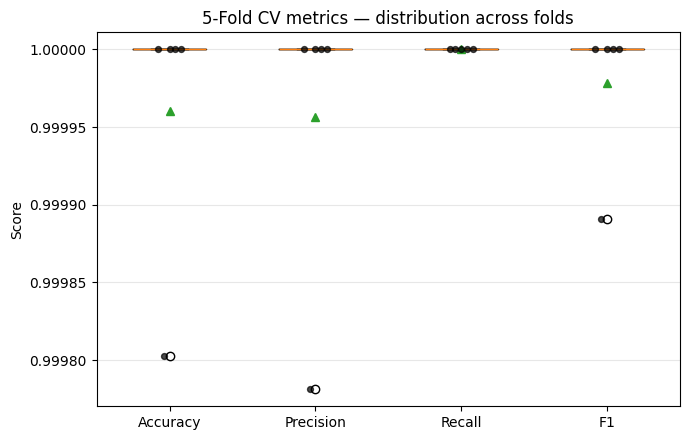

Accuracy   mean=1.0000  std=0.0001  min=0.9998  max=1.0000
Precision  mean=1.0000  std=0.0001  min=0.9998  max=1.0000
Recall     mean=1.0000  std=0.0000  min=1.0000  max=1.0000
F1         mean=1.0000  std=0.0000  min=0.9999  max=1.0000


In [22]:
metrics_names = ["acc", "precision", "recall", "f1"]
metric_labels = ["Accuracy", "Precision", "Recall", "F1"]
fold_data = [cv_results[m] for m in metrics_names]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot(fold_data, showmeans=True, widths=0.5)
ax.set_xticklabels(metric_labels)

# overlay the individual fold scores so every fold is visible
for pos, vals in enumerate(fold_data, start=1):
    jitter = np.linspace(-0.08, 0.08, len(vals))
    ax.scatter(pos + jitter, vals, color="black", s=18, alpha=0.7, zorder=3)

ax.set_ylabel("Score")
ax.set_title(f"{N_FOLDS}-Fold CV metrics — distribution across folds")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

for m, label in zip(metrics_names, metric_labels):
    v = np.array(cv_results[m])
    print(f"{label:<10} mean={v.mean():.4f}  std={v.std():.4f}  min={v.min():.4f}  max={v.max():.4f}")

### Graph 1b — Difference across folds
Each bar is a fold's score minus the mean score for that metric (0 = exactly average). Large bars mark folds that behave differently from the rest.

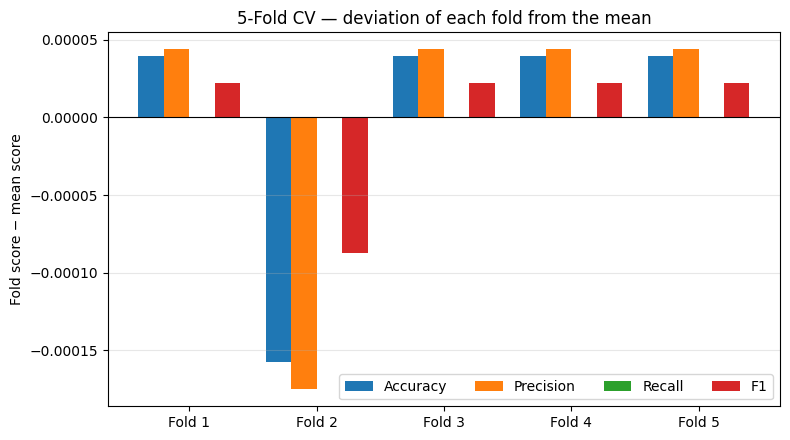

        Accuracy  Precision  Recall      F1
Fold 1    0.0000     0.0000     0.0  0.0000
Fold 2   -0.0002    -0.0002     0.0 -0.0001
Fold 3    0.0000     0.0000     0.0  0.0000
Fold 4    0.0000     0.0000     0.0  0.0000
Fold 5    0.0000     0.0000     0.0  0.0000


In [23]:
fold_ids = np.arange(1, N_FOLDS + 1)
width = 0.2

fig, ax = plt.subplots(figsize=(8, 4.5))
for k, (m, label) in enumerate(zip(metrics_names, metric_labels)):
    vals = np.array(cv_results[m])
    deviation = vals - vals.mean()
    ax.bar(fold_ids + (k - 1.5) * width, deviation, width, label=label)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(fold_ids)
ax.set_xticklabels([f"Fold {i}" for i in fold_ids])
ax.set_ylabel("Fold score − mean score")
ax.set_title(f"{N_FOLDS}-Fold CV — deviation of each fold from the mean")
ax.legend(ncol=4, loc="best")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

diff_table = pd.DataFrame({label: np.array(cv_results[m]) - np.mean(cv_results[m])
                           for m, label in zip(metrics_names, metric_labels)},
                          index=[f"Fold {i}" for i in fold_ids]).round(4)
print(diff_table.to_string())

## Stage 1 — train Transformer + fusion head (AASIST frozen)
The pretrained AASIST is used as a fixed feature extractor so the randomly-initialised transformer and fusion head cannot send noisy gradients into the pretrained weights. Full training split, early stopping on the validation split, L1 + L2 + dropout + SpecAugment.

In [35]:
# ---- Stage 1 (fast) with RESIDUAL fusion: train on cached AASIST outputs; AASIST is never run during training ----
def cache_aasist_outputs(W, split_name, batch=BATCH_SIZE):
    path = os.path.join(CACHE_DIR, f"{split_name}_aasist_feats.npy")
    if os.path.exists(path):
        A = np.load(path)
        print(f"{split_name}: loaded cached AASIST outputs {A.shape}")
        return A
    net = AASISTModel(AASIST_CFG).to(DEVICE)
    net.load_state_dict(torch.load(AASIST_WEIGHTS, map_location=DEVICE))
    net.eval()
    A = np.zeros((len(W), 5 * AASIST_CFG["gat_dims"][1] + 2), dtype=np.float32)   # [embedding(160) | logits(2)]
    with torch.no_grad():
        for i in tqdm(range(0, len(W), batch), desc=f"AASIST outputs {split_name}"):
            wave = torch.from_numpy(np.asarray(W[i:i + batch], dtype=np.float32) / 32768.0).to(DEVICE)
            emb, out = net(wave)
            A[i:i + batch] = torch.cat([emb, out], dim=1).cpu().numpy()
    del net
    np.save(path, A)
    print(f"{split_name}: cached AASIST outputs {A.shape} -> {path}")
    return A


class CachedMelAasistDataset(Dataset):
    # same interface as CachedMelWaveDataset, but the 2nd item is the cached AASIST output instead of the waveform
    def __init__(self, X, A, y):
        self.X, self.A, self.y = X, A, y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return (torch.from_numpy(self.X[idx]).unsqueeze(0), torch.from_numpy(self.A[idx]),
                torch.tensor(self.y[idx], dtype=torch.long))


class ResidualHybrid(HybridTransformerAASIST):
    """fused logits = AASIST logits + learned correction (from transformer + AASIST embeddings).
    The correction's last layer starts at zero, so training starts exactly at pretrained-AASIST behaviour."""
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        nn.init.zeros_(self.fusion[-1].weight)
        nn.init.zeros_(self.fusion[-1].bias)

    def _run(self, mel, wave):
        delta, t_logits, a_logits = super()._run(mel, wave)    # delta = fusion-head output (the correction)
        return a_logits + delta, t_logits, a_logits


A_train = cache_aasist_outputs(W_train, "train")        # loads instantly (already cached)
A_val = cache_aasist_outputs(W_val, "validation")

train_loader_s1 = DataLoader(CachedMelAasistDataset(X_train, A_train, y_train), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader_s1 = DataLoader(CachedMelAasistDataset(X_val, A_val, y_val), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

set_seed(SEED)
hybrid_model = ResidualHybrid().to(DEVICE)
hybrid_model.set_aasist_trainable(False)
hybrid_model.use_cached_aasist = True                   # 2nd input = cached AASIST output
history_s1, best_epoch_s1, cost_s1 = train_model_timed(
    hybrid_model, train_loader_s1, val_loader_s1, MAX_EPOCHS, LR, 0.0, WEIGHT_DECAY, L1_LAMBDA, PATIENCE, tag="Hybrid-stage1"
)
hybrid_model.use_cached_aasist = False                  # IMPORTANT: back to live AASIST for test scoring (waveform input)

train: loaded cached AASIST outputs (25380, 162)
validation: loaded cached AASIST outputs (24844, 162)


[Hybrid-stage1] epoch 1/30 train_loss=0.0045 train_acc=0.9987 val_loss=0.0108 val_acc=0.9973


[Hybrid-stage1] epoch 2/30 train_loss=0.0016 train_acc=0.9994 val_loss=0.0182 val_acc=0.9964


[Hybrid-stage1] epoch 3/30 train_loss=0.0015 train_acc=0.9995 val_loss=0.0114 val_acc=0.9977


[Hybrid-stage1] epoch 4/30 train_loss=0.0009 train_acc=0.9998 val_loss=0.0115 val_acc=0.9976


[Hybrid-stage1] epoch 5/30 train_loss=0.0012 train_acc=0.9997 val_loss=0.0138 val_acc=0.9971


[Hybrid-stage1] epoch 6/30 train_loss=0.0007 train_acc=0.9999 val_loss=0.0158 val_acc=0.9971
[Hybrid-stage1] early stopping at epoch 6; restoring best epoch 1 (global min val_loss=0.0108)
[Hybrid-stage1] cost: {'tag': 'Hybrid-stage1', 'epochs_run': 6, 'best_epoch': 1, 'total_train_time_sec': 172.06, 'avg_time_per_epoch_sec': 28.68, 'device': 'cuda', 'total_params': 915150, 'trainable_params': 617284}


### Graph 2 — Stage 1: Loss vs Epoch (train & val), global minimum marked

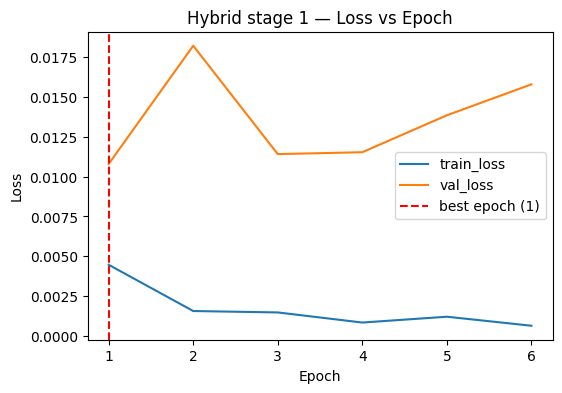

In [36]:
def plot_loss(history, title, best_epoch=None):
    epochs_range = range(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(6, 4))
    plt.plot(epochs_range, history["train_loss"], label="train_loss")
    plt.plot(epochs_range, history["val_loss"], label="val_loss")
    if best_epoch and best_epoch > 0:
        plt.axvline(best_epoch, color="red", linestyle="--", label=f"best epoch ({best_epoch})")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title)
    plt.legend()
    plt.show()

plot_loss(history_s1, "Hybrid stage 1 — Loss vs Epoch", best_epoch_s1)

### Graph 3 — Stage 1: Accuracy vs Epoch

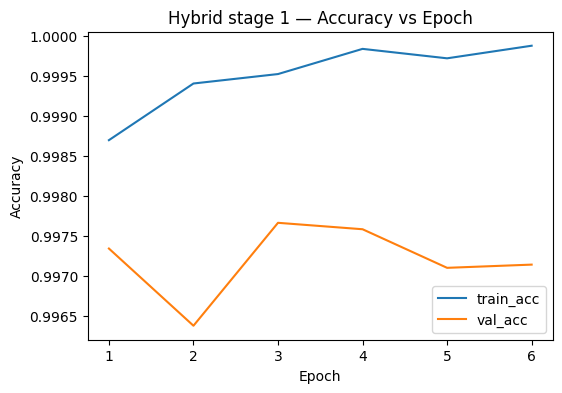

In [37]:
def plot_acc(history, title):
    epochs_range = range(1, len(history["train_acc"]) + 1)
    plt.figure(figsize=(6, 4))
    plt.plot(epochs_range, history["train_acc"], label="train_acc")
    plt.plot(epochs_range, history["val_acc"], label="val_acc")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.show()

plot_acc(history_s1, "Hybrid stage 1 — Accuracy vs Epoch")

## Computational cost summary

In [38]:
computational_cost = pd.DataFrame([cost_s1])
print(computational_cost.to_string(index=False))
computational_cost.to_csv(os.path.join(DATA_DIR, "computational_cost.csv"), index=False)

          tag  epochs_run  best_epoch  total_train_time_sec  avg_time_per_epoch_sec device  total_params  trainable_params
Hybrid-stage1           6           1                172.06                   28.68   cuda        915150            617284


## Test-set evaluation — Accuracy, Precision, Recall, F1, EER
Besides the two fused models, this also reports an **ablation** on the fine-tuned model — the transformer head alone and the AASIST head alone (read from the same forward pass) — and the **pretrained AASIST with no training at all**, so you can see what each component contributes.

In [ ]:
test_results = {}

def add_result(name, scores, labels):
    eer, thr = compute_eer(scores, labels)
    preds = (scores > thr).astype(int)
    print(f"--- {name} (threshold={thr:.4f}) ---")
    print(classification_report(labels, preds, target_names=["bonafide", "spoof"], zero_division=0))
    print(f"EER: {eer*100:.2f}%\n")
    test_results[name] = {"scores": scores, "labels": labels, "preds": preds, "eer": eer}

s1_scores, labels_test = get_all_scores(hybrid_model, test_loader)
za_scores, _ = get_aasist_zero_shot_scores(test_loader)

add_result("Hybrid (stage 1)", s1_scores["fused"], labels_test)
add_result("Ablation: transformer head only", s1_scores["transformer"], labels_test)
add_result("AASIST pretrained, no training here", za_scores, labels_test)

scoring:  10%|███████▎                                                              | 309/2969 [02:04<18:19,  2.42it/s]

## Full metrics table (Accuracy, Precision, Recall, F1, Specificity, ROC-AUC) → results.csv
Adds specificity (true-negative rate) and an explicit ROC-AUC number per model, and saves everything the rubric asks for into a single `results.csv`.

In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score

results_rows = []
for name, res in test_results.items():
    labels, preds, scores = res["labels"], res["preds"], res["scores"]
    cm = confusion_matrix(labels, preds)
    tn, fp, fn, tp = cm.ravel()
    specificity = tn / (tn + fp) if (tn + fp) > 0 else float("nan")
    acc = accuracy_score(labels, preds)
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)
    prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(labels, preds, average="weighted", zero_division=0)
    prec_per_class, rec_per_class, f1_per_class, _ = precision_recall_fscore_support(labels, preds, average=None, zero_division=0)
    roc_auc_val = roc_auc_score(labels, scores)

    results_rows.append({
        "model": name,
        "accuracy": round(acc, 4),
        "precision_macro": round(prec_macro, 4),
        "recall_macro": round(rec_macro, 4),
        "f1_macro": round(f1_macro, 4),
        "precision_weighted": round(prec_w, 4),
        "recall_weighted": round(rec_w, 4),
        "f1_weighted": round(f1_w, 4),
        "precision_bonafide": round(prec_per_class[0], 4),
        "recall_bonafide": round(rec_per_class[0], 4),
        "f1_bonafide": round(f1_per_class[0], 4),
        "precision_spoof": round(prec_per_class[1], 4),
        "recall_spoof": round(rec_per_class[1], 4),
        "f1_spoof": round(f1_per_class[1], 4),
        "specificity": round(specificity, 4),
        "roc_auc": round(roc_auc_val, 4),
        "eer_pct": round(res["eer"] * 100, 2),
    })

results_table = pd.DataFrame(results_rows)
print(results_table.to_string(index=False))
results_table.to_csv(os.path.join(DATA_DIR, "results.csv"), index=False)

best_name = results_table.sort_values("eer_pct").iloc[0]["model"]
best_row = results_table[results_table["model"] == best_name].iloc[0]
print(f"\nHeadline result -- {best_name}:")
print(f"  Spoof precision = {best_row['precision_spoof']*100:.2f}%")
print(f"  Spoof recall    = {best_row['recall_spoof']*100:.2f}%")
print(f"  Accuracy        = {best_row['accuracy']*100:.2f}%")
print(f"  EER             = {best_row['eer_pct']:.2f}%")

### Headline result (generated live from `results_table`, not hard-coded)
As this is an AI-generated speech detection model, we primarily focus on spoof-class metrics. The exact numbers are printed by the cell above, computed from `results_table`, so this can never go stale.

**Note on the decision threshold.** Accuracy, precision, recall, F1, specificity and the confusion matrices are computed at each model's EER operating point on the test scores (the threshold is chosen using the test labels). EER and ROC-AUC do not depend on a threshold. Because the threshold is set at the EER point, spoof recall, bonafide recall (specificity) and accuracy come out nearly equal.

### Graph 6 — Confusion matrices

In [ ]:
def plot_confusion(labels, preds, title):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(4, 4))
    plt.imshow(cm, cmap="Blues")
    plt.title(title)
    plt.colorbar()
    plt.xticks([0, 1], ["bonafide", "spoof"])
    plt.yticks([0, 1], ["bonafide", "spoof"])
    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

for name, res in test_results.items():
    plot_confusion(res["labels"], res["preds"], f"{name} — Confusion Matrix")

### Graph 7 — ROC curve

In [ ]:
plt.figure(figsize=(5, 5))
for name, res in test_results.items():
    fpr, tpr, _ = roc_curve(res["labels"], res["scores"])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

### Graph 8 — Precision-Recall curve

In [ ]:
plt.figure(figsize=(5, 5))
for name, res in test_results.items():
    prec, rec, _ = precision_recall_curve(res["labels"], res["scores"])
    plt.plot(rec, prec, label=name)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()

## CO4 — Comparison with Published Baselines and State-of-the-Art Systems (ASVspoof2019 LA)

The published rows are copied from the cited papers; accuracy / precision / recall / F1 / AUC are **NR (Not Reported)** there because the official metric is EER / min t-DCF, and are not estimated here. Rows marked "this notebook" are measured on **this notebook's test split with the EER-threshold protocol** described above.

> **Read the AASIST rows carefully.** The published AASIST number (0.83% EER) comes from the authors' own protocol and pipeline. The "AASIST pretrained, no training here" row runs the same released weights through *this notebook's* data pipeline and test split, so it is the fair like-for-like reference for the hybrid. If the hybrid does not beat that row, the transformer branch is not adding anything on this data.

**References:**
- Todisco et al., "ASVspoof 2019: Future Horizons in Spoofed and Fake Audio Detection", *Interspeech 2019* — LFCC+GMM, LFCC+LCNN baselines.
- Tak et al., "End-to-End Anti-Spoofing with RawNet2", *ICASSP 2021* — RawNet2 (parameter count from Truong et al. 2025).
- Jung et al., "AASIST: Audio Anti-Spoofing using Integrated Spectro-Temporal Graph Attention Networks", *ICASSP 2022* — AASIST, ~0.30M parameters.

In [ ]:
def _row(model_name, label, params):
    r = results_table[results_table["model"] == model_name].iloc[0]
    return {"model": label, "accuracy": r["accuracy"], "precision": r["precision_spoof"], "recall": r["recall_spoof"],
            "f1": r["f1_spoof"], "eer_pct": r["eer_pct"], "auc": r["roc_auc"], "parameters": params}

aasist_params = sum(p.numel() for p in AASISTModel(AASIST_CFG).parameters())

sota_comparison = pd.DataFrame([
    {"model": "LFCC + GMM (ASVspoof2019 baseline B1) -- classical baseline", "accuracy": "NR", "precision": "NR", "recall": "NR",
     "f1": "NR", "eer_pct": 15.80, "auc": "NR", "parameters": "NR (GMM, non-DL)"},
    {"model": "LFCC + LCNN -- CNN-based reference architecture", "accuracy": "NR", "precision": "NR", "recall": "NR",
     "f1": "NR", "eer_pct": 9.26, "auc": "NR", "parameters": "NR"},
    {"model": "RawNet2 -- published deep-learning system", "accuracy": "NR", "precision": "NR", "recall": "NR",
     "f1": "NR", "eer_pct": 9.50, "auc": "NR", "parameters": "17.6M (Truong et al. 2025 re-implementation)"},
    {"model": "AASIST -- as published (authors' own pipeline)", "accuracy": "NR", "precision": "NR", "recall": "NR",
     "f1": "NR", "eer_pct": 0.83, "auc": "NR", "parameters": "0.30M (Jung et al. 2022)"},
    _row("AASIST pretrained, no training here", "AASIST pretrained -- this notebook's pipeline/test split", aasist_params),
    _row("Hybrid (stage 1)", "Proposed: AudioTransformer + AASIST (stage 1, AASIST frozen)", total_params),
])
print(sota_comparison.to_string(index=False))
print("\nNR = Not Reported in the cited publication; not estimated or reconstructed.")
sota_comparison.to_csv(os.path.join(DATA_DIR, "comparison.csv"), index=False)

**Discussion.**
The proposed system is a hybrid: a small `nn.TransformerEncoder`-based model over log-mel patches (global self-attention across time and frequency) combined with the pretrained AASIST graph-attention network over the raw waveform. The two see the signal differently — AASIST via a learnable sinc front-end and spectro-temporal graph attention, the transformer via a fixed mel representation — so fusing their embeddings is meant to give complementary evidence against unseen attacks.

Fill in the numbers from the tables above rather than from this text: compare "Hybrid (fine-tuned)" against "AASIST pretrained, no training here" (same pipeline, same test split) for the real gain from the transformer branch, and use the two ablation rows to see whether the fused head beats each branch alone. Note that AASIST has roughly half the parameters of the transformer branch, so parameter count is not what separates the models here; the hybrid's cost is mainly the raw-waveform branch's compute and the extra waveform cache on disk.

## Bias / Variance summary

- The 5-fold CV **mean** is the average performance across folds; the **standard deviation** is fold-to-fold variability (not statistical bias/variance, which is better read from the train/val loss curves).
- Dropout, L1 (transformer branch), L2 (AdamW `weight_decay`), SpecAugment, gradient clipping and early stopping are all in place to keep the train/val gap small.
- **CV optimism:** the pretrained AASIST branch was trained on all of the training split, so CV metrics overstate generalisation (see the caveat above the CV cell). Use the validation curves and the held-out test table for the honest picture.
- Read the best epochs and loss minima off Graphs 2 and 4 (stage 1 / stage 2). Because dropout and L1 are active only in training mode, validation loss can sit below training loss without that indicating a problem.

## CV / validation performance vs. held-out test performance

ASVspoof2019 LA's evaluation partition contains spoofing attacks that do not appear in the training/development data, so validation and CV scores are expected to be much higher than test scores. Compare the validation accuracy in Graph 5 and the CV summary with the test accuracy/EER in `results_table`: a large gap is a **generalisation gap to unseen attacks**, not training instability. Class balance is nearly identical across splits, so imbalance does not explain it. The "AASIST pretrained" and ablation rows show how much of the test performance comes from each branch.

## Save models + history

In [ ]:
torch.save(hybrid_model.state_dict(), DATA_DIR + r"\hybrid_transformer_aasist_stage1.pt")

with open(DATA_DIR + r"\hybrid_stage1_history.json", "w") as f:
    json.dump(history_s1, f)
with open(DATA_DIR + r"\cv_results.json", "w") as f:
    json.dump(cv_results, f)

for fname in ["dataset_distribution.csv", "preprocessing_params.csv", "hyperparameter_tuning_log.csv",
              "computational_cost.csv", "results.csv", "comparison.csv"]:
    fpath = os.path.join(DATA_DIR, fname)
    print(fname, "OK" if os.path.exists(fpath) else "MISSING")